# Classical ML Models for Cardiovascular Disease Prediction
### Explainable Artificial Intelligence for CVD Prediction — Q1 Paper

**Models:** Decision Tree · Naive Bayes · k-NN · Logistic Regression · Random Forest · SVM (RBF) · MLP (Neural Network)  
**Dataset:** Heart_disease_clean.csv  

---
**Sections:**
1. Install & Import Libraries
2. Load & Preprocess Data
3. Feature Engineering
4. Train / Validation / Test Split
5. Train All 7 Models
6. Performance Comparison Table
7. ROC Curves — All Models
8. Confusion Matrices
9. Precision-Recall Curves
10. SHAP — MLP (Proposed Model)
11. Permutation Importance — MLP
12. Summary

## 1. Install & Import Libraries

In [1]:
!pip install shap scikit-learn pandas numpy matplotlib seaborn -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

# ── 7 Models ──────────────────────────────────────────────────
from sklearn.tree          import DecisionTreeClassifier
from sklearn.naive_bayes   import GaussianNB
from sklearn.neighbors     import KNeighborsClassifier
from sklearn.linear_model  import LogisticRegression
from sklearn.ensemble      import RandomForestClassifier
from sklearn.svm           import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, average_precision_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('All libraries imported successfully!')
print(f'Scikit-learn version : {__import__("sklearn").__version__}')

All libraries imported successfully!
Scikit-learn version : 1.7.2


## 2. Load & Preprocess Data

In [3]:
df = pd.read_csv('Heart_disease_clean.csv')

print('Dataset shape:', df.shape)
print('\nColumns:')
for i, col in enumerate(df.columns):
    print(f'  [{i}] {col}')
print('\nTarget distribution:')
print(df['cardiovascular disease'].value_counts())
print('\nMissing values:', df.isnull().sum().sum())

Dataset shape: (68653, 11)

Columns:
  [0] Gender (0: female, 1: male)
  [1] age(years)
  [2] BMI
  [3] ap_hi(Systolic blood pressure)
  [4] ap_lo(Diastolic blood pressure)
  [5] cholesterol(1: normal, 2: above normal, 3: well above normal)
  [6] Glucose(1: normal, 2: above normal, 3: well above normal)
  [7] smoking
  [8] alcohol
  [9] active
  [10] cardiovascular disease

Target distribution:
cardiovascular disease
does not have cardiovascular disease    34706
has cardiovascular disease              33947
Name: count, dtype: int64

Missing values: 0


In [4]:
# ── Encode target ─────────────────────────────────────────────
df['target'] = (df['cardiovascular disease'] == 'has cardiovascular disease').astype(int)
df = df.drop(columns=['cardiovascular disease'])

print('Target: 1 = CVD  |  0 = No CVD')
print(df['target'].value_counts())

Target: 1 = CVD  |  0 = No CVD
target
0    34706
1    33947
Name: count, dtype: int64


In [5]:
# ── Remove physiologically impossible rows ────────────────────
before = len(df)
df['PP_check'] = df['ap_hi(Systolic blood pressure)'] - df['ap_lo(Diastolic blood pressure)']
df = df[df['BMI'].between(10, 60) & (df['PP_check'] > 0)].reset_index(drop=True)
df = df.drop(columns=['PP_check'])
print(f'Rows: {before} → {len(df)}  (removed {before - len(df)})')

Rows: 68653 → 68534  (removed 119)


## 3. Feature Engineering

In [6]:
# ── Engineer 3 haemodynamic features ─────────────────────────
df['PP']  = df['ap_hi(Systolic blood pressure)'] - df['ap_lo(Diastolic blood pressure)']
df['MAP'] = (df['ap_hi(Systolic blood pressure)'] + 2 * df['ap_lo(Diastolic blood pressure)']) / 3
df['risk_count'] = (
    (df['cholesterol(1: normal, 2: above normal, 3: well above normal)'] > 1).astype(int) +
    (df['Glucose(1: normal, 2: above normal, 3: well above normal)'] > 1).astype(int) +
    df['smoking'] + df['alcohol'] + (1 - df['active'])
)

FEATURES = [
    'Gender (0: female, 1: male)', 'age(years)', 'BMI',
    'ap_hi(Systolic blood pressure)', 'ap_lo(Diastolic blood pressure)',
    'cholesterol(1: normal, 2: above normal, 3: well above normal)',
    'Glucose(1: normal, 2: above normal, 3: well above normal)',
    'smoking', 'alcohol', 'active', 'PP', 'MAP', 'risk_count'
]

FEAT_NAMES = ['Gender','Age','BMI','SBP','DBP',
              'Cholesterol','Glucose','Smoking',
              'Alcohol','Active','PP','MAP','RiskCount']

X = df[FEATURES].values
y = df['target'].values

print(f'Feature matrix : {X.shape}')
print(f'Target vector  : {y.shape}')

Feature matrix : (68534, 13)
Target vector  : (68534,)


## 4. Train / Validation / Test Split (70 / 15 / 15)

In [7]:
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.1765, random_state=RANDOM_STATE, stratify=y_tmp
)

print(f'Train : {X_train.shape[0]:>6} ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'Val   : {X_val.shape[0]:>6} ({X_val.shape[0]/len(X)*100:.1f}%)')
print(f'Test  : {X_test.shape[0]:>6} ({X_test.shape[0]/len(X)*100:.1f}%)')

# Scale — fitted on train only
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)
print('\nStandardScaler fitted on training data only.')

Train :  47971 (70.0%)
Val   :  10282 (15.0%)
Test  :  10281 (15.0%)

StandardScaler fitted on training data only.


## 5. Train All 7 Models

In [8]:
# ── Model 1: Decision Tree ────────────────────────────────────
print('Training 1/7: Decision Tree ...')
dt_model = DecisionTreeClassifier(
    max_depth        = 8,
    min_samples_leaf = 10,
    random_state     = RANDOM_STATE
)
dt_model.fit(X_train_sc, y_train)
dt_proba = dt_model.predict_proba(X_test_sc)[:, 1]
dt_pred  = dt_model.predict(X_test_sc)
print(f'  DT  AUC={roc_auc_score(y_test, dt_proba):.4f}  '
      f'Acc={accuracy_score(y_test, dt_pred):.4f}  '
      f'F1={f1_score(y_test, dt_pred):.4f}')

Training 1/7: Decision Tree ...
  DT  AUC=0.7915  Acc=0.7272  F1=0.7144


In [9]:
# ── Model 2: Naive Bayes ──────────────────────────────────────
print('Training 2/7: Naive Bayes ...')
nb_model = GaussianNB()
nb_model.fit(X_train_sc, y_train)
nb_proba = nb_model.predict_proba(X_test_sc)[:, 1]
nb_pred  = nb_model.predict(X_test_sc)
print(f'  NB  AUC={roc_auc_score(y_test, nb_proba):.4f}  '
      f'Acc={accuracy_score(y_test, nb_pred):.4f}  '
      f'F1={f1_score(y_test, nb_pred):.4f}')

Training 2/7: Naive Bayes ...
  NB  AUC=0.7849  Acc=0.7192  F1=0.6823


In [10]:
# ── Model 3: k-Nearest Neighbours ────────────────────────────
print('Training 3/7: k-NN ...')
knn_model = KNeighborsClassifier(
    n_neighbors = 11,
    weights     = 'distance',
    n_jobs      = -1
)
knn_model.fit(X_train_sc, y_train)
knn_proba = knn_model.predict_proba(X_test_sc)[:, 1]
knn_pred  = knn_model.predict(X_test_sc)
print(f'  kNN AUC={roc_auc_score(y_test, knn_proba):.4f}  '
      f'Acc={accuracy_score(y_test, knn_pred):.4f}  '
      f'F1={f1_score(y_test, knn_pred):.4f}')

Training 3/7: k-NN ...
  kNN AUC=0.7390  Acc=0.6973  F1=0.6911


In [11]:
# ── Model 4: Logistic Regression ──────────────────────────────
print('Training 4/7: Logistic Regression ...')
lr_model = LogisticRegression(
    C            = 1.0,
    max_iter     = 1000,
    random_state = RANDOM_STATE,
    n_jobs       = -1
)
lr_model.fit(X_train_sc, y_train)
lr_proba = lr_model.predict_proba(X_test_sc)[:, 1]
lr_pred  = lr_model.predict(X_test_sc)
print(f'  LR  AUC={roc_auc_score(y_test, lr_proba):.4f}  '
      f'Acc={accuracy_score(y_test, lr_pred):.4f}  '
      f'F1={f1_score(y_test, lr_pred):.4f}')

Training 4/7: Logistic Regression ...
  LR  AUC=0.7929  Acc=0.7312  F1=0.7107


In [12]:
# ── Model 5: Random Forest ────────────────────────────────────
print('Training 5/7: Random Forest ...')
rf_model = RandomForestClassifier(
    n_estimators     = 300,
    max_depth        = 10,
    min_samples_leaf = 5,
    max_features     = 'sqrt',
    random_state     = RANDOM_STATE,
    n_jobs           = -1
)
rf_model.fit(X_train_sc, y_train)
rf_proba = rf_model.predict_proba(X_test_sc)[:, 1]
rf_pred  = rf_model.predict(X_test_sc)
print(f'  RF  AUC={roc_auc_score(y_test, rf_proba):.4f}  '
      f'Acc={accuracy_score(y_test, rf_pred):.4f}  '
      f'F1={f1_score(y_test, rf_pred):.4f}')

Training 5/7: Random Forest ...
  RF  AUC=0.7995  Acc=0.7322  F1=0.7112


In [13]:
# ── Model 6: SVM (RBF kernel) ─────────────────────────────────
# Note: SVM is slow on large datasets — uses 30% subsample for training
print('Training 6/7: SVM (RBF) — this may take a few minutes ...')
np.random.seed(RANDOM_STATE)
svm_idx   = np.random.choice(len(X_train_sc), size=int(len(X_train_sc) * 0.3), replace=False)
svm_model = SVC(
    kernel      = 'rbf',
    C           = 1.0,
    gamma       = 'scale',
    probability = True,
    random_state= RANDOM_STATE
)
svm_model.fit(X_train_sc[svm_idx], y_train[svm_idx])
svm_proba = svm_model.predict_proba(X_test_sc)[:, 1]
svm_pred  = svm_model.predict(X_test_sc)
print(f'  SVM AUC={roc_auc_score(y_test, svm_proba):.4f}  '
      f'Acc={accuracy_score(y_test, svm_pred):.4f}  '
      f'F1={f1_score(y_test, svm_pred):.4f}')

Training 6/7: SVM (RBF) — this may take a few minutes ...
  SVM AUC=0.7901  Acc=0.7311  F1=0.7071


In [14]:
# ── Model 7: MLP Neural Network (Proposed) ───────────────────
print('Training 7/7: MLP Neural Network ...')
mlp_model = MLPClassifier(
    hidden_layer_sizes = (16, 16),
    activation         = 'relu',
    alpha              = 1e-5,      # L2 regularisation
    learning_rate_init = 0.001,
    solver             = 'adam',
    max_iter           = 500,
    early_stopping     = True,
    validation_fraction= 0.1,
    random_state       = RANDOM_STATE
)
mlp_model.fit(X_train_sc, y_train)
mlp_proba = mlp_model.predict_proba(X_test_sc)[:, 1]
mlp_pred  = mlp_model.predict(X_test_sc)
print(f'  MLP AUC={roc_auc_score(y_test, mlp_proba):.4f}  '
      f'Acc={accuracy_score(y_test, mlp_pred):.4f}  '
      f'F1={f1_score(y_test, mlp_pred):.4f}')
print('\n✓ All 7 models trained.')

Training 7/7: MLP Neural Network ...
  MLP AUC=0.7980  Acc=0.7330  F1=0.7176

✓ All 7 models trained.


## 6. Performance Comparison Table

In [15]:
# ── Build results table ───────────────────────────────────────
model_results = {
    'Decision Tree'      : (dt_proba,  dt_pred),
    'Naive Bayes'        : (nb_proba,  nb_pred),
    'k-NN'               : (knn_proba, knn_pred),
    'Logistic Regression': (lr_proba,  lr_pred),
    'Random Forest'      : (rf_proba,  rf_pred),
    'SVM (RBF)'          : (svm_proba, svm_pred),
    'MLP (Proposed)'     : (mlp_proba, mlp_pred),
}

rows = []
for name, (proba, pred) in model_results.items():
    rows.append({
        'Model'    : name,
        'AUC'      : roc_auc_score(y_test, proba),
        'Accuracy' : accuracy_score(y_test, pred),
        'F1'       : f1_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall'   : recall_score(y_test, pred)
    })

results_df = pd.DataFrame(rows).set_index('Model').sort_values('AUC', ascending=False)

print('=' * 72)
print('   MODEL PERFORMANCE COMPARISON (Test Set) — sorted by AUC')
print('=' * 72)
print(f'{"Model":<22} {"AUC":>7} {"Accuracy":>9} {"F1":>8} {"Precision":>11} {"Recall":>8}')
print('-' * 72)
for model, m in results_df.iterrows():
    marker = ' ← BEST' if model == results_df.index[0] else ''
    print(f'{model:<22} {m["AUC"]:>7.4f} {m["Accuracy"]:>9.4f} '
          f'{m["F1"]:>8.4f} {m["Precision"]:>11.4f} {m["Recall"]:>8.4f}{marker}')
print('=' * 72)

   MODEL PERFORMANCE COMPARISON (Test Set) — sorted by AUC
Model                      AUC  Accuracy       F1   Precision   Recall
------------------------------------------------------------------------
Random Forest           0.7995    0.7322   0.7112      0.7618   0.6669 ← BEST
MLP (Proposed)          0.7980    0.7330   0.7176      0.7522   0.6860
Logistic Regression     0.7929    0.7312   0.7107      0.7593   0.6679
Decision Tree           0.7915    0.7272   0.7144      0.7403   0.6903
SVM (RBF)               0.7901    0.7311   0.7071      0.7659   0.6567
Naive Bayes             0.7849    0.7192   0.6823      0.7742   0.6099
k-NN                    0.7390    0.6973   0.6911      0.6975   0.6848


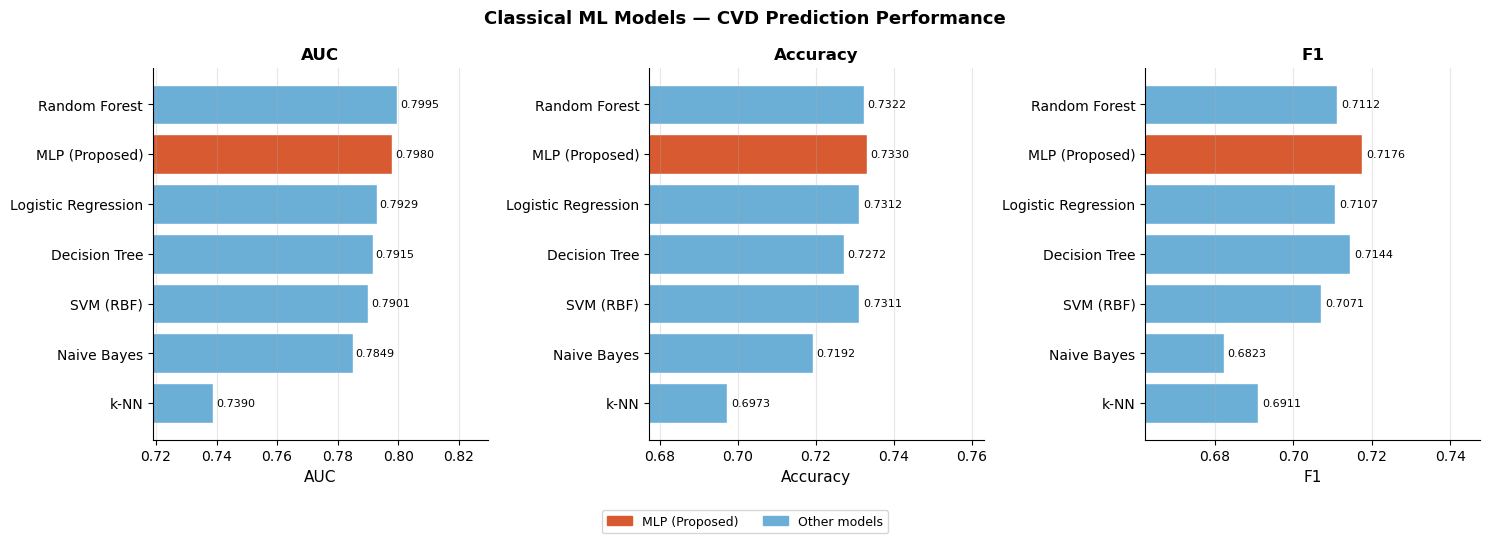

Saved: classical_models_comparison.png


In [16]:
# ── Bar chart comparison ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Classical ML Models — CVD Prediction Performance', fontsize=13, fontweight='bold')

palette = ['#D85A30' if m == 'MLP (Proposed)' else '#6BAED6' for m in results_df.index]

for ax, metric in zip(axes, ['AUC', 'Accuracy', 'F1']):
    vals = results_df[metric].values
    bars = ax.barh(results_df.index, vals, color=palette, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=8)
    ax.set_xlabel(metric, fontsize=11)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xlim(min(vals) - 0.02, max(vals) + 0.03)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

from matplotlib.patches import Patch
fig.legend(handles=[
    Patch(color='#D85A30', label='MLP (Proposed)'),
    Patch(color='#6BAED6', label='Other models')
], loc='lower center', ncol=2, fontsize=9, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig('classical_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: classical_models_comparison.png')

## 7. ROC Curves — All 7 Models

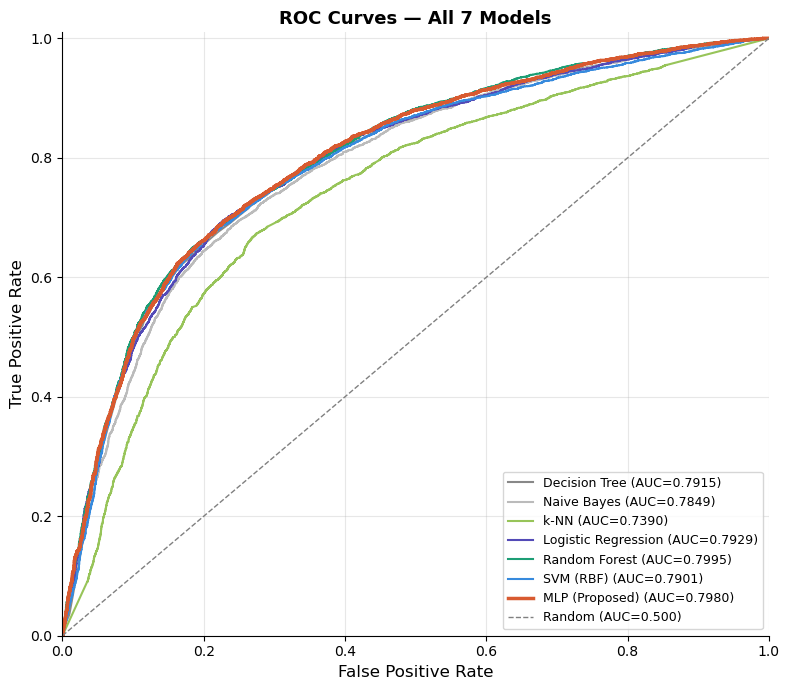

Saved: roc_curves_classical.png


In [17]:
palette_roc = ['#888888','#BBBBBB','#97C459','#534AB7','#1D9E75','#378ADD','#D85A30']

fig, ax = plt.subplots(figsize=(8, 7))
for (name, (proba, _)), color in zip(model_results.items(), palette_roc):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val     = roc_auc_score(y_test, proba)
    lw = 2.5 if name == 'MLP (Proposed)' else 1.5
    ax.plot(fpr, tpr, color=color, lw=lw, label=f'{name} (AUC={auc_val:.4f})')

ax.plot([0,1],[0,1],'--', color='gray', lw=1, label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All 7 Models', fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.set_xlim([0,1]); ax.set_ylim([0,1.01])
ax.grid(alpha=0.3)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('roc_curves_classical.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: roc_curves_classical.png')

## 8. Confusion Matrices — All 7 Models

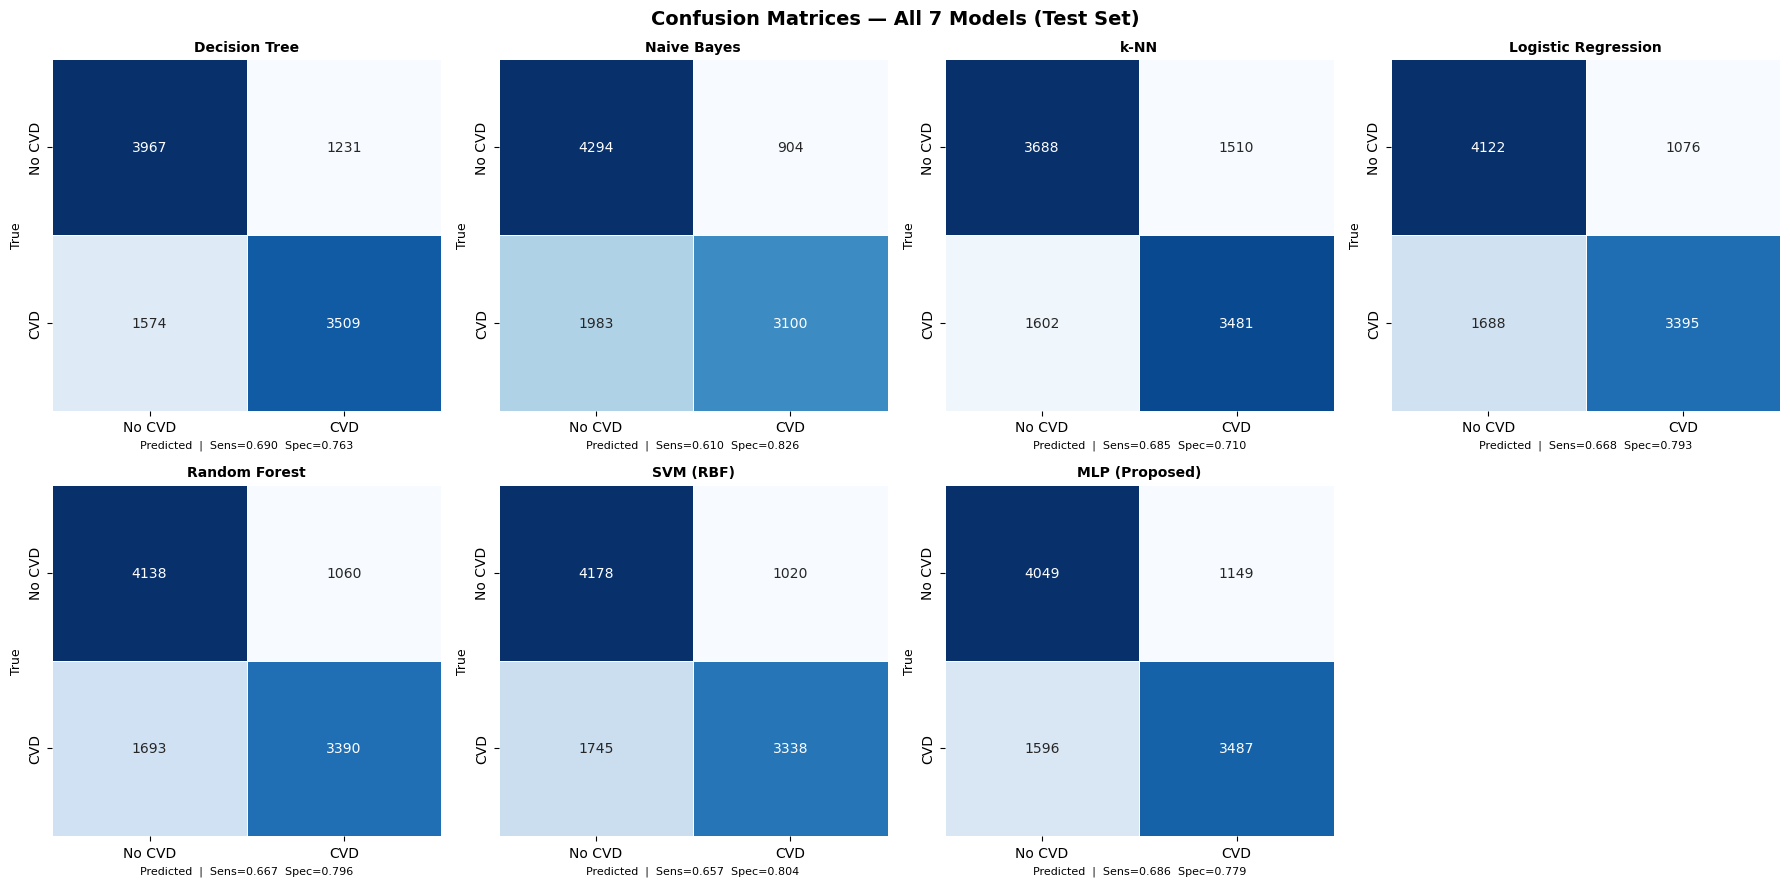

Saved: confusion_matrices_all.png


In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
fig.suptitle('Confusion Matrices — All 7 Models (Test Set)', fontsize=14, fontweight='bold')

for ax, (name, (_, pred)) in zip(axes, model_results.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['No CVD','CVD'],
                yticklabels=['No CVD','CVD'],
                linewidths=0.5, ax=ax, cbar=False)
    ax.set_title(name, fontsize=10, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=9)
    ax.set_ylabel('True', fontsize=9)
    tn, fp, fn, tp = cm.ravel()
    ax.set_xlabel(f'Predicted  |  Sens={tp/(tp+fn):.3f}  Spec={tn/(tn+fp):.3f}', fontsize=8)

# Hide the 8th empty subplot
axes[7].set_visible(False)

plt.tight_layout()
plt.savefig('confusion_matrices_all.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion_matrices_all.png')

## 9. Precision-Recall Curves

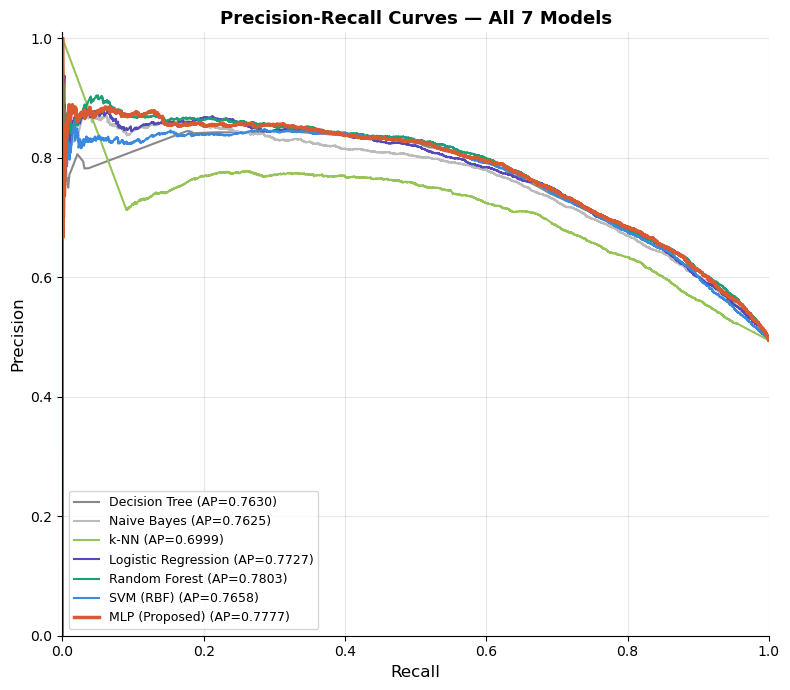

Saved: pr_curves_classical.png


In [19]:
fig, ax = plt.subplots(figsize=(8, 7))
for (name, (proba, _)), color in zip(model_results.items(), palette_roc):
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap           = average_precision_score(y_test, proba)
    lw = 2.5 if name == 'MLP (Proposed)' else 1.5
    ax.plot(rec, prec, color=color, lw=lw, label=f'{name} (AP={ap:.4f})')

ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curves — All 7 Models', fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='lower left')
ax.set_xlim([0,1]); ax.set_ylim([0,1.01])
ax.grid(alpha=0.3)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('pr_curves_classical.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: pr_curves_classical.png')

## 10. SHAP Explainability — MLP (Proposed Model)

In [20]:
# ── SHAP for MLP using KernelExplainer ───────────────────────
print('Computing SHAP values for MLP...')
print('(Uses 300 background samples — takes ~2-3 minutes)')

bg_idx      = np.random.choice(len(X_train_sc), 300, replace=False)
background  = X_train_sc[bg_idx]

explainer   = shap.KernelExplainer(mlp_model.predict_proba, background)
shap_values = explainer.shap_values(X_test_sc[:300], nsamples=100)

# For binary classification KernelExplainer returns list [class0, class1]
sv = shap_values[1] if isinstance(shap_values, list) else shap_values

X_test_df = pd.DataFrame(X_test_sc[:300], columns=FEAT_NAMES)
print('SHAP values computed.')

Using 300 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


Computing SHAP values for MLP...
(Uses 300 background samples — takes ~2-3 minutes)


  0%|          | 0/300 [00:00<?, ?it/s]

SHAP values computed.


<Figure size 800x500 with 0 Axes>

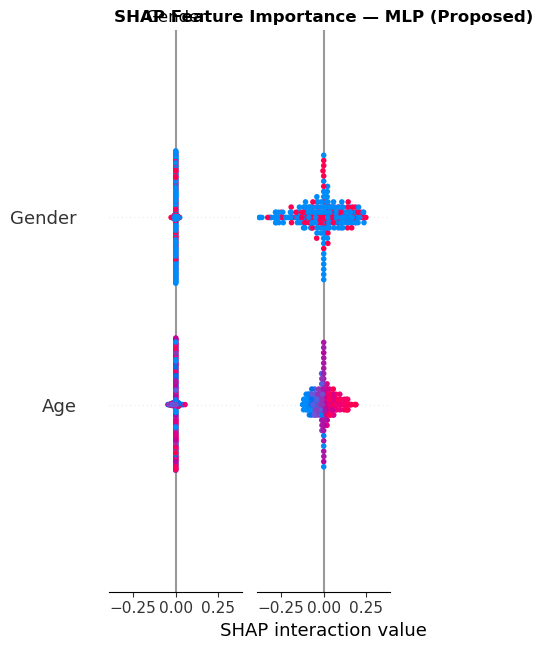

Saved: shap_bar_mlp.png


In [21]:
# ── SHAP bar plot ─────────────────────────────────────────────
plt.figure(figsize=(8, 5))
shap.summary_plot(sv, X_test_df, plot_type='bar', show=False)
plt.title('SHAP Feature Importance — MLP (Proposed)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_bar_mlp.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_bar_mlp.png')

<Figure size 800x600 with 0 Axes>

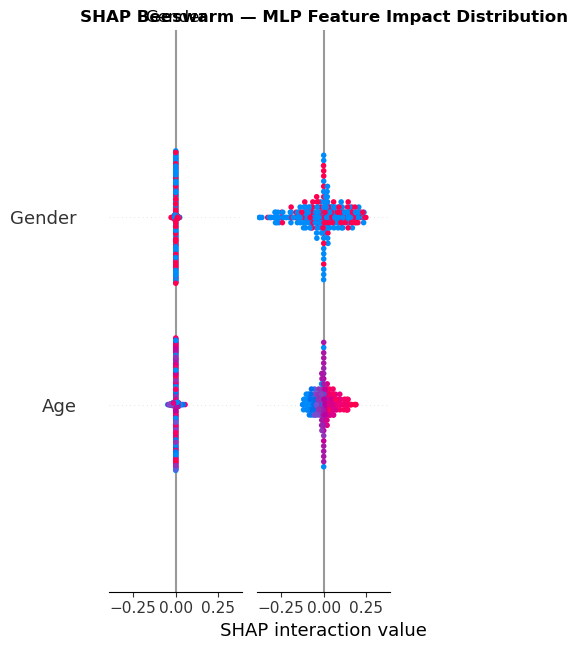

Saved: shap_beeswarm_mlp.png


In [22]:
# ── SHAP beeswarm plot ────────────────────────────────────────
plt.figure(figsize=(8, 6))
shap.summary_plot(sv, X_test_df, show=False)
plt.title('SHAP Beeswarm — MLP Feature Impact Distribution', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_beeswarm_mlp.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_beeswarm_mlp.png')

Patient index : 6438
P(CVD)        : 0.9675
True label    : 1  (1=CVD)


  0%|          | 0/1 [00:00<?, ?it/s]

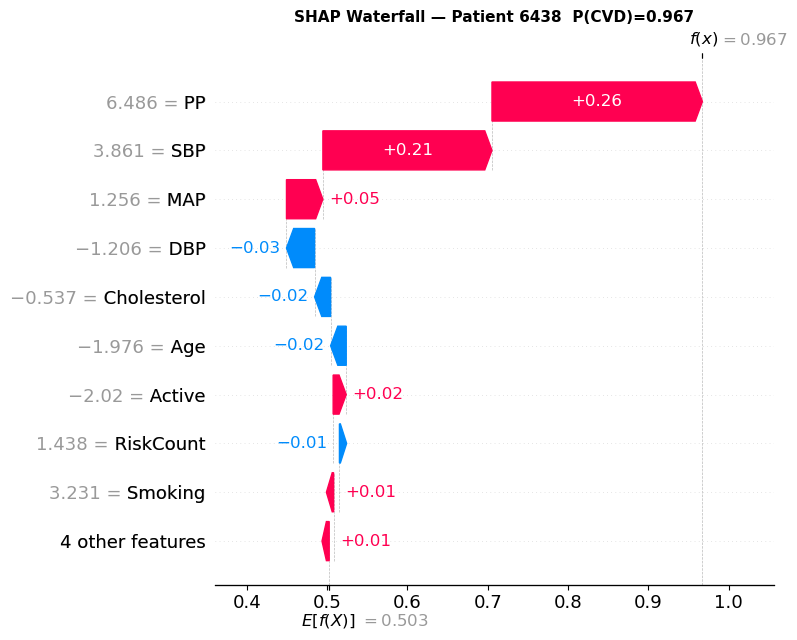

Saved: shap_waterfall_mlp.png


In [26]:
# ── SHAP Waterfall — MLP (single cell, fully self-contained) ──────────

# Step 1: Pick best true-positive patient (from full test set)
tp_mask = (y_test == 1) & (mlp_pred == 1)
p_idx   = int(np.where(tp_mask)[0][np.argmax(mlp_proba[tp_mask])])
print(f"Patient index : {p_idx}")
print(f"P(CVD)        : {mlp_proba[p_idx]:.4f}")
print(f"True label    : {y_test[p_idx]}  (1=CVD)")

# Step 2: Recompute SHAP for this single patient only
sv_single = explainer.shap_values(X_test_sc[p_idx : p_idx + 1])

# Extract class-1 values
if isinstance(sv_single, list):
    shap_vals_class1 = sv_single[1][0]
elif sv_single.ndim == 3:
    shap_vals_class1 = sv_single[0, :, 1]
else:
    shap_vals_class1 = sv_single[0]

# Step 3: Build Explanation object
base = (explainer.expected_value[1]
        if isinstance(explainer.expected_value, (list, np.ndarray))
        else explainer.expected_value)

exp = shap.Explanation(
    values        = shap_vals_class1,
    base_values   = base,
    data          = X_test_sc[p_idx],        # ← fix: numpy array, not X_test_df.iloc
    feature_names = FEAT_NAMES
)

# Step 4: Plot and save
plt.figure(figsize=(9, 6))
shap.plots.waterfall(exp, show=False)
plt.title(f'SHAP Waterfall — Patient {p_idx}  P(CVD)={mlp_proba[p_idx]:.3f}',
          fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_waterfall_mlp.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_waterfall_mlp.png')

## 11. Permutation Importance — MLP

Computing permutation importance (10 repeats)...

Permutation Importance (Mean decrease in ROC-AUC):
    Feature  Importance      Std
Cholesterol    0.042875 0.001977
        Age    0.032874 0.001612
         PP    0.026437 0.001306
        SBP    0.021922 0.000638
        DBP    0.016994 0.000639
        MAP    0.012048 0.000660
     Active    0.005893 0.000991
        BMI    0.005118 0.000459
  RiskCount    0.003350 0.000793
    Glucose    0.003174 0.000557
     Gender    0.000575 0.000364
    Smoking    0.000470 0.000227
    Alcohol    0.000380 0.000227


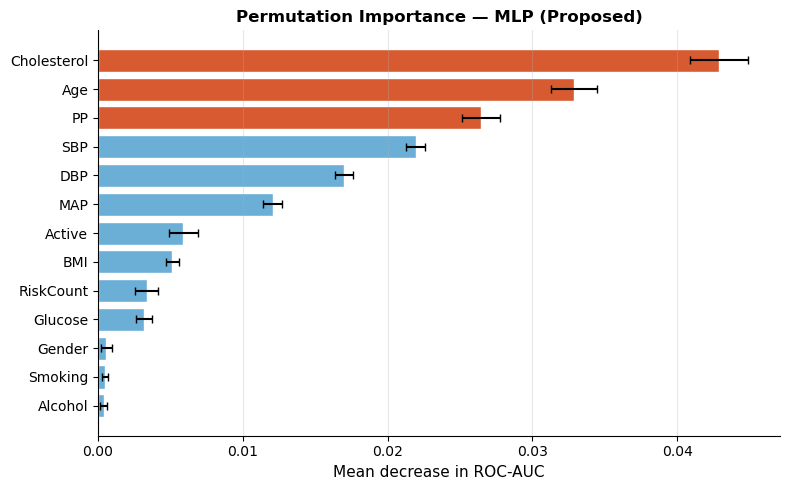

Saved: permutation_importance_mlp.png


In [27]:
# ── Permutation importance (drop in ROC-AUC) ─────────────────
print('Computing permutation importance (10 repeats)...')
perm = permutation_importance(
    mlp_model, X_test_sc, y_test,
    scoring    = 'roc_auc',
    n_repeats  = 10,
    random_state = RANDOM_STATE,
    n_jobs     = -1
)

perm_df = pd.DataFrame({
    'Feature'   : FEAT_NAMES,
    'Importance': perm.importances_mean,
    'Std'       : perm.importances_std
}).sort_values('Importance', ascending=False)

print('\nPermutation Importance (Mean decrease in ROC-AUC):')
print(perm_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
colors_p = ['#D85A30' if v > perm_df['Importance'].quantile(0.75) else '#6BAED6'
            for v in perm_df['Importance']]
ax.barh(perm_df['Feature'][::-1], perm_df['Importance'][::-1],
        xerr=perm_df['Std'][::-1], color=colors_p[::-1],
        edgecolor='white', capsize=3)
ax.set_xlabel('Mean decrease in ROC-AUC', fontsize=11)
ax.set_title('Permutation Importance — MLP (Proposed)', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('permutation_importance_mlp.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: permutation_importance_mlp.png')

## 12. Final Summary

In [28]:
print('=' * 72)
print('   FINAL RESULTS — ALL 7 CLASSICAL MODELS (Test Set)')
print('=' * 72)
print(f'{"Model":<22} {"AUC":>7} {"Accuracy":>9} {"F1":>8} {"Precision":>11} {"Recall":>8}')
print('-' * 72)
for model, m in results_df.iterrows():
    marker = ' ← BEST' if model == results_df.index[0] else ''
    marker = ' ← PROPOSED' if model == 'MLP (Proposed)' else marker
    print(f'{model:<22} {m["AUC"]:>7.4f} {m["Accuracy"]:>9.4f} '
          f'{m["F1"]:>8.4f} {m["Precision"]:>11.4f} {m["Recall"]:>8.4f}{marker}')
print('=' * 72)

print('\nOutput files saved:')
files = [
    'classical_models_comparison.png',
    'roc_curves_classical.png',
    'confusion_matrices_all.png',
    'pr_curves_classical.png',
    'shap_bar_mlp.png',
    'shap_beeswarm_mlp.png',
    'shap_waterfall_mlp.png',
    'permutation_importance_mlp.png'
]
for f in files:
    print(f'  {f}')

   FINAL RESULTS — ALL 7 CLASSICAL MODELS (Test Set)
Model                      AUC  Accuracy       F1   Precision   Recall
------------------------------------------------------------------------
Random Forest           0.7995    0.7322   0.7112      0.7618   0.6669 ← BEST
MLP (Proposed)          0.7980    0.7330   0.7176      0.7522   0.6860 ← PROPOSED
Logistic Regression     0.7929    0.7312   0.7107      0.7593   0.6679
Decision Tree           0.7915    0.7272   0.7144      0.7403   0.6903
SVM (RBF)               0.7901    0.7311   0.7071      0.7659   0.6567
Naive Bayes             0.7849    0.7192   0.6823      0.7742   0.6099
k-NN                    0.7390    0.6973   0.6911      0.6975   0.6848

Output files saved:
  classical_models_comparison.png
  roc_curves_classical.png
  confusion_matrices_all.png
  pr_curves_classical.png
  shap_bar_mlp.png
  shap_beeswarm_mlp.png
  shap_waterfall_mlp.png
  permutation_importance_mlp.png


In [29]:
# ── LAST CELL — Save test-set predictions for statistical analysis ────
import numpy as np, os

np.save('y_test.npy',     y_test)
np.save('proba_dt.npy',   dt_proba);   np.save('pred_dt.npy',   dt_pred)
np.save('proba_nb.npy',   nb_proba);   np.save('pred_nb.npy',   nb_pred)
np.save('proba_knn.npy',  knn_proba);  np.save('pred_knn.npy',  knn_pred)
np.save('proba_lr.npy',   lr_proba);   np.save('pred_lr.npy',   lr_pred)
np.save('proba_rf.npy',   rf_proba);   np.save('pred_rf.npy',   rf_pred)
np.save('proba_svm.npy',  svm_proba);  np.save('pred_svm.npy',  svm_pred)
np.save('proba_mlp.npy',  mlp_proba);  np.save('pred_mlp.npy',  mlp_pred)

# Confirm all files saved correctly
saved = ['y_test','proba_dt','pred_dt','proba_nb','pred_nb',
         'proba_knn','pred_knn','proba_lr','pred_lr',
         'proba_rf','pred_rf','proba_svm','pred_svm',
         'proba_mlp','pred_mlp']

print("Files saved:")
for name in saved:
    fname = f"{name}.npy"
    arr   = np.load(fname)
    print(f"  ✓  {fname:<22}  shape={arr.shape}")

Files saved:
  ✓  y_test.npy              shape=(10281,)
  ✓  proba_dt.npy            shape=(10281,)
  ✓  pred_dt.npy             shape=(10281,)
  ✓  proba_nb.npy            shape=(10281,)
  ✓  pred_nb.npy             shape=(10281,)
  ✓  proba_knn.npy           shape=(10281,)
  ✓  pred_knn.npy            shape=(10281,)
  ✓  proba_lr.npy            shape=(10281,)
  ✓  pred_lr.npy             shape=(10281,)
  ✓  proba_rf.npy            shape=(10281,)
  ✓  pred_rf.npy             shape=(10281,)
  ✓  proba_svm.npy           shape=(10281,)
  ✓  pred_svm.npy            shape=(10281,)
  ✓  proba_mlp.npy           shape=(10281,)
  ✓  pred_mlp.npy            shape=(10281,)
